# Экспериментальное исследование влияния параметров алгоритмов хранения паролей на вычислительные затраты

## Импорт библиотек

In [1]:
import time
import os
import hashlib
import warnings
import ast
from pathlib import Path

import bcrypt
from argon2 import PasswordHasher
from argon2.low_level import hash_secret_raw, Type
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
warnings.filterwarnings('ignore')

%matplotlib inline 

plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

Path('results').mkdir(exist_ok=True)
Path('figures').mkdir(exist_ok=True)

In [3]:
passwords = []

with open("input_data/passwords.txt", 'r', encoding='utf-8') as f:
    for pwd in f:
        pwd = pwd.rstrip('\r\n')

        if pwd.startswith(("b'", 'b"')):
            pwd = ast.literal_eval(pwd).decode('utf-8')

        if pwd:
            passwords.append(pwd)

print(f"Загружено паролей: {len(passwords)}")

Загружено паролей: 1000


## Функция замеров

In [4]:
def measure_time(func, *args, **kwargs):
    start_time = time.perf_counter()
    result = func(*args, **kwargs)
    end_time = time.perf_counter()

    time_ms = (end_time - start_time) * 1000

    return result, time_ms

## Эксперимент

### Bcrypt

In [5]:
def hash_bcrypt(password, cost_factor):
    salt = bcrypt.gensalt(rounds=cost_factor)
    return bcrypt.hashpw(password.encode('utf-8'), salt)

In [6]:
def run_bcrypt_experiment(passwords, cost_factors, repeats=100):
    results = []

    for cost in cost_factors:
        print(f"Тестируем bcrypt с cost={cost}...")

        times = []

        hash_bcrypt(passwords[0], cost)

        for i in range(repeats):
            pwd = passwords[i % len(passwords)]

            res, time_res = measure_time(hash_bcrypt, pwd, cost)

            times.append(time_res)

        median_time = np.median(times)
        std_time = np.std(times, ddof=1) if repeats > 1 else 0

        results.append({
            'algorithm': 'bcrypt',
            'parameter_name': 'cost_factor',
            'parameter_value': cost,
            'time_ms': round(median_time, 3),
            'std_ms': round(std_time, 3)
        })

    return results

In [7]:
cost_factors_to_test = [4, 6, 8, 10, 12]

bcrypt_results = run_bcrypt_experiment(passwords, cost_factors_to_test, repeats=100)

Тестируем bcrypt с cost=4...
Тестируем bcrypt с cost=6...
Тестируем bcrypt с cost=8...
Тестируем bcrypt с cost=10...
Тестируем bcrypt с cost=12...


In [8]:
df_bcrypt = pd.DataFrame(bcrypt_results)
df_bcrypt.to_csv('results/bcrypt_results.csv', index=False)
df_bcrypt

,algorithm,parameter_name,parameter_value,time_ms,std_ms
0,bcrypt,cost_factor,4,0.687,0.090
1,bcrypt,cost_factor,6,2.647,0.121
2,bcrypt,cost_factor,8,10.484,0.119
3,bcrypt,cost_factor,10,42.223,0.931
4,bcrypt,cost_factor,12,169.372,3.608


### Argon2

In [9]:
def hash_argon2(password, memory_cost, time_cost=3):
    ph = PasswordHasher(time_cost=time_cost, memory_cost=memory_cost, parallelism=4, type=Type.ID)
    return ph.hash(password)

In [10]:
def run_argon2_experiment(passwords, memory_costs, repeats=100):
    results = []

    for mem_cost in memory_costs:
        print(f"Тестируем Argon2 с memory_cost={mem_cost} КиБ...")

        times = []

        hash_argon2(passwords[0], mem_cost)

        for i in range(repeats):
            pwd = passwords[i % len(passwords)]

            res, time_res = measure_time(hash_argon2, pwd, mem_cost)

            times.append(time_res)

        median_time = np.median(times)
        std_time = np.std(times, ddof=1) if repeats > 1 else 0

        results.append({
            'algorithm': 'Argon2id',
            'parameter_name': 'memory_cost_kib',
            'parameter_value': mem_cost,
            'time_ms': round(median_time, 3),
            'std_ms': round(std_time, 3),
            'memory_cost_mib': mem_cost / 1024
        })

    return results

In [11]:
memory_costs_to_test = [16384, 32768, 65536, 131072] # 16 МБ, 32 МБ, 64 МБ и 128 МБ соответсвенно
argon2_results = run_argon2_experiment(passwords, memory_costs_to_test, repeats=100)

df_argon2 = pd.DataFrame(argon2_results)
df_argon2.to_csv('results/argon2_results.csv', index=False)
df_argon2

Тестируем Argon2 с memory_cost=16384 КиБ...
Тестируем Argon2 с memory_cost=32768 КиБ...
Тестируем Argon2 с memory_cost=65536 КиБ...
Тестируем Argon2 с memory_cost=131072 КиБ...


,algorithm,parameter_name,parameter_value,time_ms,std_ms,memory_cost_mib
0,Argon2id,memory_cost_kib,16384,9.611,1.557,16.0
1,Argon2id,memory_cost_kib,32768,17.812,0.543,32.0
2,Argon2id,memory_cost_kib,65536,35.737,0.738,64.0
3,Argon2id,memory_cost_kib,131072,72.456,3.022,128.0


### PBKDF2

In [12]:
def hash_pbkdf2(password, iterations):
    salt = b'some_fixed_salt_123'
    return hashlib.pbkdf2_hmac('sha256', password.encode('utf-8'), salt, iterations)

In [13]:
def run_pbkdf2_experiment(passwords, iterations_list, repeats=100):
    results = []

    for iters in iterations_list:
        print(f"Тестируем PBKDF2 с iterations={iters}...")

        times = []

        hash_pbkdf2(passwords[0], iters)

        for i in range(repeats):
            pwd = passwords[i % len(passwords)]

            res, time_res = measure_time(hash_pbkdf2, pwd, iters)

            times.append(time_res)

        median_time = np.median(times)
        std_time = np.std(times, ddof=1) if repeats > 1 else 0

        results.append({
            'algorithm': 'PBKDF2',
            'parameter_name': 'iterations',
            'parameter_value': iters,
            'time_ms': round(median_time, 3),
            'std_ms': round(std_time, 3)
        })

    return results

In [14]:
iterations_to_test = [10000, 50000, 100000, 200000, 500000]
pbkdf2_results = run_pbkdf2_experiment(passwords, iterations_to_test, repeats=100)

df_pbkdf2 = pd.DataFrame(pbkdf2_results)
df_pbkdf2.to_csv('results/pbkdf2_results.csv', index=False)
df_pbkdf2

Тестируем PBKDF2 с iterations=10000...
Тестируем PBKDF2 с iterations=50000...
Тестируем PBKDF2 с iterations=100000...
Тестируем PBKDF2 с iterations=200000...
Тестируем PBKDF2 с iterations=500000...


,algorithm,parameter_name,parameter_value,time_ms,std_ms
0,PBKDF2,iterations,10000,2.707,0.522
1,PBKDF2,iterations,50000,13.791,0.488
2,PBKDF2,iterations,100000,27.439,1.914
3,PBKDF2,iterations,200000,54.574,2.224
4,PBKDF2,iterations,500000,136.623,7.266


## Вывод результатов

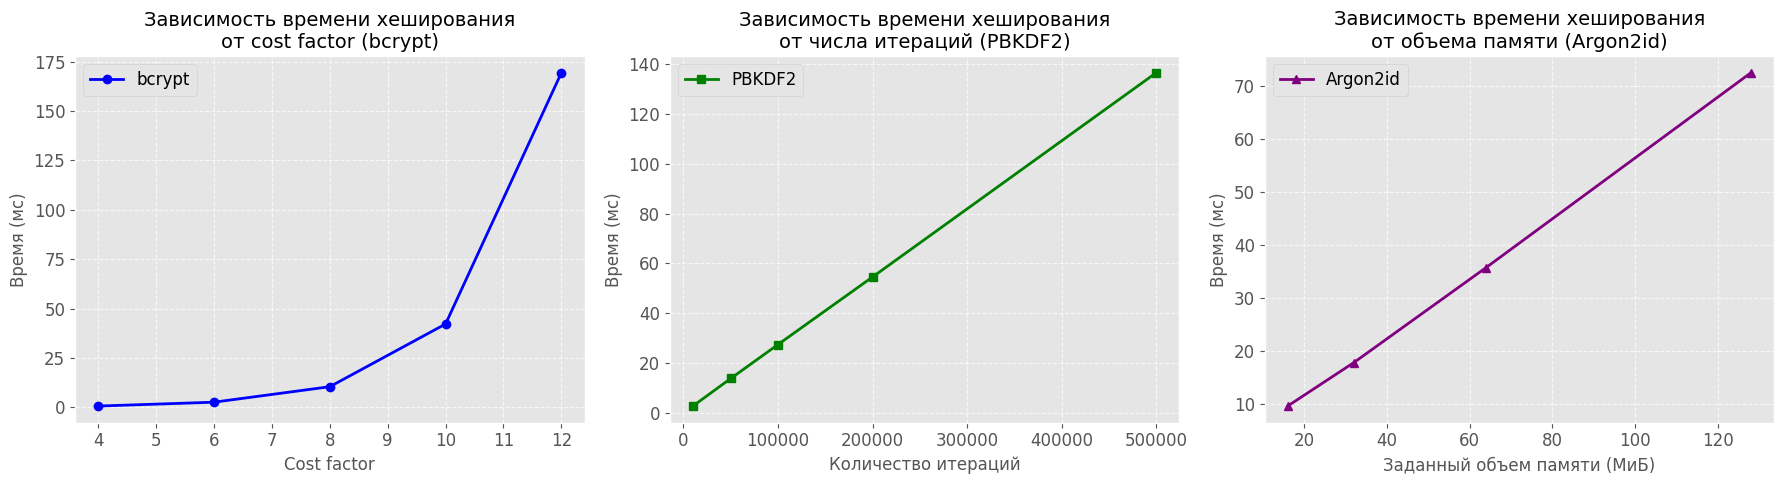

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Bcrypt
ax1 = axes[0]

ax1.plot(df_bcrypt['parameter_value'], df_bcrypt['time_ms'],
         marker='o', linewidth=2, color='blue', label='bcrypt')

ax1.set_title('Зависимость времени хеширования\nот cost factor (bcrypt)', fontsize=14)
ax1.set_xlabel('Cost factor', fontsize=12)
ax1.set_ylabel('Время (мс)', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend()


# PBKDF2
ax2 = axes[1]

ax2.plot(df_pbkdf2['parameter_value'], df_pbkdf2['time_ms'],
         marker='s', linewidth=2, color='green', label='PBKDF2')

ax2.set_title('Зависимость времени хеширования\nот числа итераций (PBKDF2)', fontsize=14)
ax2.set_xlabel('Количество итераций', fontsize=12)
ax2.set_ylabel('Время (мс)', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend()


# Argon2
ax3 = axes[2]

ax3.plot(df_argon2['memory_cost_mib'], df_argon2['time_ms'],
         marker='^', linewidth=2, color='purple', label='Argon2id')

ax3.set_title('Зависимость времени хеширования\nот объема памяти (Argon2id)', fontsize=14)
ax3.set_xlabel('Заданный объем памяти (МиБ)', fontsize=12)
ax3.set_ylabel('Время (мс)', fontsize=12)
ax3.grid(True, linestyle='--', alpha=0.7)
ax3.legend()


plt.tight_layout()
plt.savefig('figures/comparison_plots.png', dpi=300)
plt.show()